# Scaled Dot-Product Attention

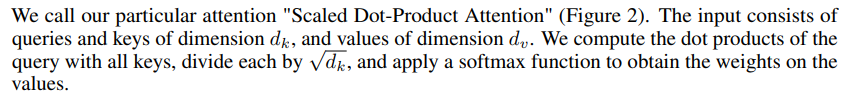

Para essa implementação a atenção maxima deve ser em relação aos shapes das matrizes:
- Q, K, V shapes: [L, dim]
- Q @ K.T : [Lq, Lk]

## 1. Qual problema o Attention resolve?

Antes do surgimento da arquitetura dos Transformers proposta pelo paper "Attention Is All You Need", os RNNs (Recurrent Neural Networks) eram a principal arquitetura utilizada. Entretando, quanto maior era a sequência processada, mais dificil era preservar informações relevantes de posições distantes, dificultando aprender dependências de longo prazo.

Para melhorar esse cenário, foram desenvolvidas arquiteturas como LSTMs e GRUs, as quais foram desenvolvidas para melhorar a capacidade das RNNs de aprender dependências de longo prazo, ajudando a preservar e atualizar informações relevantes ao longo do processamento sequencial. Apesar dessa melhora, essas arquiteturas tinham uma característica em comum: processar tokens de maneira sequencial e as dificuldades de aprendizado de dependências de longo prazo limitavam a capacidade dessas arquiteturas de capturar relações entre tokens distantes.

Visando superar essas limitações, vamos parar um pouco e analisar como processamos uma frase normalmente:

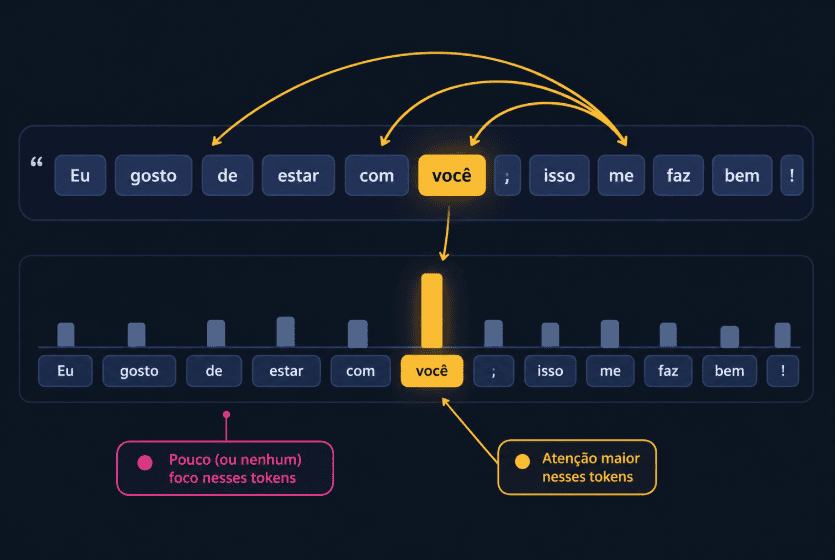

Perceba que ao lermos a palavra "me", tendemos a prestar mais anteção em palavras como "você" e atribuir menos relevância a palavras como "de". A ideia do Attention é semelhante: entender quais tokens são relevantes para a representação de um determinado token, atribuindo diferentes pesos de atenção as posições da sequência.

A parte interessante dessa abordagem é que ela pode ser fortemente paralelizada, pois podemos calcular simultaneamente as relações entre os diferentes tokens da sequência.

## 2. Embeddings e Projeção de Matrizes

Para um entendimento inicial, vamo trabalhar o Attention na seguinte sentença: "Meu pequeno Curumim", a qual terá uma representação numérica via embeddings:

[imagem dos embeddings]

A matriz X é a matriz de representações de entrada, onde cada uma de suas linhas contém os embeddings de tokens referentes a cada token e o número de colunas equivale a dimensão dos embeddings.

### 2.1. Query, Key e Value

Para prosseguirmos com o mecanismo de atenção precisamos de 3 novas matrizes:
- **QUERY** -> Matriz que corresponde a quais informações estamos procurando
- **KEY**   -> Matriz utilizada para calcular a compatibilidade com cada query
- **VALUE** -> Matriz que corresponde a informação que poderá contribuir para a representação contextualizada de outro token

É importante entender, nesse ponto, que essas 3 matrizes serão projeções dos dados originais multiplicados por pesos diferentes (sendo mais objetivo, aplicando uma camada linear nesse ponto).

Apesar de todas partirem do mesmo conjunto de entrada X, cada projeção possui seus próprios pesos aprendíveis, permitindo que sejam desenvolvidas representações distintas para cada finalidade.

obs: O termo Self ( de sef-attention ) indica que as matrizes Q, K e V são projetadas a partir da mesma sequência de entrada.

[ imagem projetando a matriz X em Q,K e V]

Note que os as matrizes dos pesos são multiplicadas pelas representações de entrada gerando, respectivamente, as matrizes Q, K e V. Inicialmente, os pesos dessas projeções são inicializados e ainda não estão ajustados para a tarefa. Ao decorrer do treinamento, especificamente durante a otimização desse modelo, esses padrões são continuamente identificados e o pesos são ajustados para finalidade da atenção.

### 2.2. Attention Scores

Para continuar falando sobre attention, recomendo fortemente pararmos e analisarmos o que é **produto escalar**.

> O produto escalar é uma operação fundamental da álgebra linear que combina dois vetores para produzir um único número real (escalar), também conhecido como produto interno.  Geometricamente, ele mede o quanto dois vetores apontam na mesma direção, sendo calculado pelo produto das magnitudes dos vetores e do cosseno do ângulo entre eles.

[ imagem mostrando como o produto escalar representa bem proximidade e distância entre pontos em um espaço vetorial ]

Nesse contexto podemos entender o produto escalar como medida de compatibilidade entre Queries e Keys que também aplica um fator de escala para controlar a magnitude dos scores.

Aplicando justamente nessas matrizes temos uma matriz que contém os scores de compatibilidade entre cada token representado por uma query e cada token representado por uma key, onde quanto maior for o produto escalar, mais relacionados estão entre si.

[ imagem do token Q com a legenda ao lado apotando qual o token representado por linha e o K ao lado com a mesma informação ]

Relembrando rapidamente, para que duas matrizes possam ser multiplicadas é necessário que a coluna da primeira seja igual o número e linhas da segunda. Posteriormente, o formato da matriz resultante será o número de linhas da primeira e o número de colunas da segunda. 

- Por exemplo:
- Q: dimensão (L x d_k)
- K: dimensão (L x d_k)
- K^T: dimensão (d_k x L)
- Resultado: dimensão (L x L)

Objetivando poder multiplicar as matrizes Q e K, vamos transpor a segunda matriz para que possa corresponder ao formato esperado. Caso não se lembra, transpor uma matriz consiste simplesmente em trocar o número de linhas pelo número de colunas.

[ imagem, com legenda, mostrando a multiplicação das matrizes e mostrando a attention score matrix - o exemplo deve conter valores muito altos para mostrar a importância de escalar ]

Nesse momento já temos como analisar a relação entre tokens de forma visual, por exemplo [ quando eu colocar a imagem coloco um exemplo ].

### 2.3. Importância de Escalar Os Attention Scores

Ao obter os resultados podemos ter valores extremamente altos que podem prejudicar a proxima etapa do attention: aplicar o softmax. 

Caso haja um valor muito alto isso pode colapsar o softmax, pois apresentam diferenças muito grandes, a distribuição resultante pode ficar extremamente concentrada. Uma posição recebe uma probabilidade próxima de 1, enquanto as demais recebem probabilidades próximas de 0. 

Isso gera saturação no softmax.

[ imagem com softmax colapsado ]

Para evitar problemas de gradiente e no softmax, o ideal é escalar os dados resentes na matriz de Attention Scores. O paper propõe como alternativa dividir todos os dados da matriz por $\sqrt{d_k}$, onde d_k é a dimensão da matriz K. (revisar)

[ mostrando todos os dados dividdidos por d_k -> resultado dos dados escalados em matriz]

Dessa forma, controlamos a magnitude dos valores antes da aplicação do Softmax, ajudando a evitar sua saturação e favorecendo o fluxo dos gradientes durante o treinamento.

Com os Attention Scores escalados, podemos prosseguir para a proxima etapa do Attention.

### 2.4. Softmax

Com os dados devidamente estabilizados, o softmax introduz uma distribuição probabilistica, onde cada número pode ser analisado como uma probabilidade e a soma de todas as probabilidades de relação entre uma palavra e as outras resulta em 1:

[ mostrar uma linha da tabela com o softmax aplicado ]

Mas como podemos fazer isso?

Uma ideia inicial seria simplesmente dividir cada valor pela soma de todos os valores da linha correspondente. Dessa forma, cada elemento representaria uma fração do total, fazendo com que a soma dos resultados fosse igual a 1.

[ imagem mostrando essa etapa simples ]

Entretanto, o que acontece caso haja um valor negativo e a soma resulte em zero? Isso significaria dividir por zero, o que é uma indifinição matemática.

Para evitar isso existe um truque exponencial: tornar o cada valor um expoente do número de Euller (e). A vantagem disso é que todos os valores projetados serão positivos, mesmo que o valor inicial seja negativo.

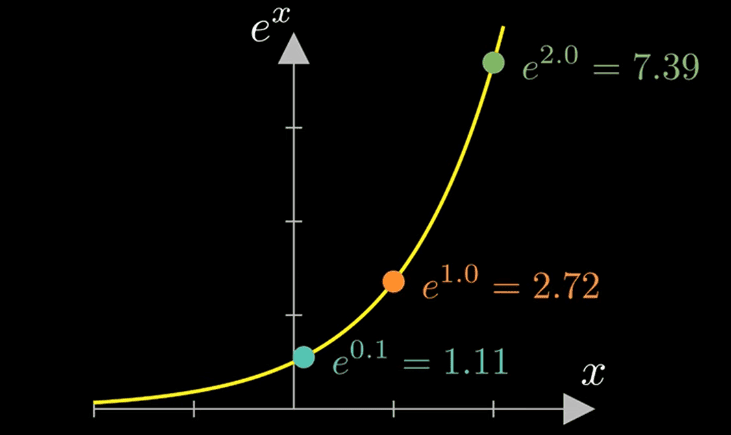

Agora, para finalizar, podemos aplicar a ideia de dividir cada elemento pelo somatório de todos - utilizando a base (e) e o valor no expoente.

$$
\operatorname{softmax}(z_i) =
\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

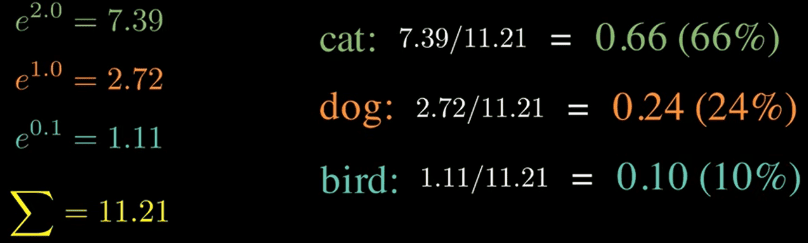

Com isso, obtemos uma distribuição de pesos de atenção, permitindo analisar como cada Query distribui sua atenção entre as Keys disponíveis.

### 2.5. Máscaras

Em determinados pontos do treinamento é importante mascarar alguns tokens para que esses não interfiram no treinamento do modelo naquele determinado ponto ou mascarar para que eles nunca auxiliem no cálculo do gadiente, para deixar mais claro vou falar dos 2 tipos de mascaras que precisamos entender.

1. Máscaras de Padding:

Para que os dados de um modelo possam ser armazenados em uma matriz X de entrada, é importante que todas as frases tenham um mesmo tamanho ( para que tenham um mesmo número de tokens e , consequentemente, embeddings).

[ montar uma imagem exatamente de uma matrix x coom frases diferentes -> matriz de tokens diferentes -> matriz dos embeddings -> matriz com paddings]

Com o objetivo desse formato ser respeitado, é necessário adicionar um token especial chamado < pad > em sentenças com número de dimensão menores que o da matriz de entrada X.

Porém isso introduz um pequeno **problema**. Ao treinar o modelo, Cada query é comparada com todas as keys disponíveis, se não aplicarmos a máscara uma posição de padding poderá receber um score e ao criar a matriz de attention scores ( Q*K^T ) teremos probabilidades diferentes de 0 para essas posições.

Com a finalidade de impedir isso, criamos uma máscara chamada **MÁSCARA DE PADDING**, que substitui os valores (na attention score) associado a posições corrependentes a pading por -infinito. Mas por qual motivo -infinito?

Lembre que durante o cálculo do softmax os valores se tornam expoentes de (e), e se elevarmos , tems e^-inf = 0. Ou seja, a distribuição probabilística zera nesses pontos e eles não influenciam nesse cálculo.

[ imagem substituindo por -inf -> imagem aós softmax como valores iguuais a 0]

 
2. Máscaras Causais 

Durante o treinamento, o Transformer pode processar todos os tokens da sequência alvo em paralelo. Mas isso introduz outro pequeno problema: cada posição poderia acessar informações de tokens futuros. Queremos que cada posição aprenda a prever o próximo token utilizando somente as informações disponíveis até aquele momento.

Para impedir isso, criamos uma **MÁSCARA CAUSAL**, que substitui os attention scores associados as posições futuras por (-\infty), assim como na mascara anterior, antes de aplicar o softmax.

Assim como na máscara anterior, essas posições recebem probabilidade zero. Dessa forma, cada token pode considerar apenas a si mesmo e os tokens anteriores.

[Imagem mostrando a aplicação da máscara causal e a matriz de probabilidades após o Softmax]


### 2.6. Multiplicar Por V

Nesse ponto o valor de $\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)$ já foi calculado, e podemos compreende-lo como os pesos das relações entre as palavras. Por exemplo, considerando que a palavra "gato" em dada sequência tenha sido representado pelo vetor [ 0  0.3  0.4  0.1  0  0.2 ] podemos entender que a palavra gato é mais relacionada com as palavras na posição 1, 2, 3 e 5 da sequência.

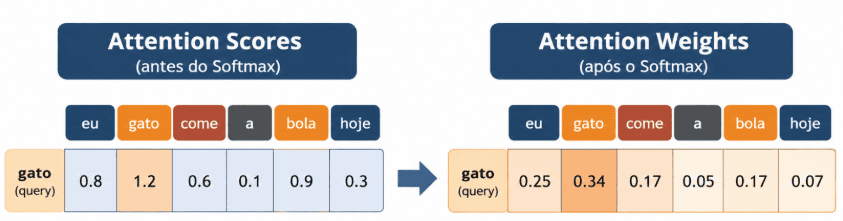

A partir do momento que aplicamos o softmax podemos interpretar  os attention scores como attention weights, pois mostram a distribuição probabilistica da relação entre tokens, sendo um vetor que representa justamente a relação entre o token analisado (gato) e os demais tokens da sequência. 

Entretando isso não significa que elas adicionam esse contexto ao vetor original para modificar sua representação de embeddings. Para isso utilizamos justamente a matriz de Value, que contém justamente representações projetadas dos tokens de entrada. E ao multiplicá-la pelos attention weights, obtemos representações contextualizadas, nas quais cada posição incorpora informações de outras posições da sequência de acordo com os pesos de atenção calculados.

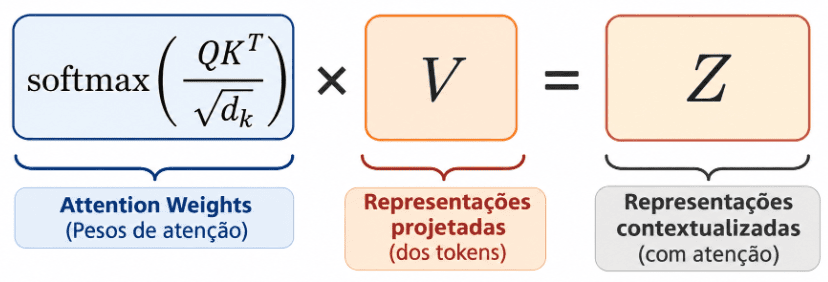

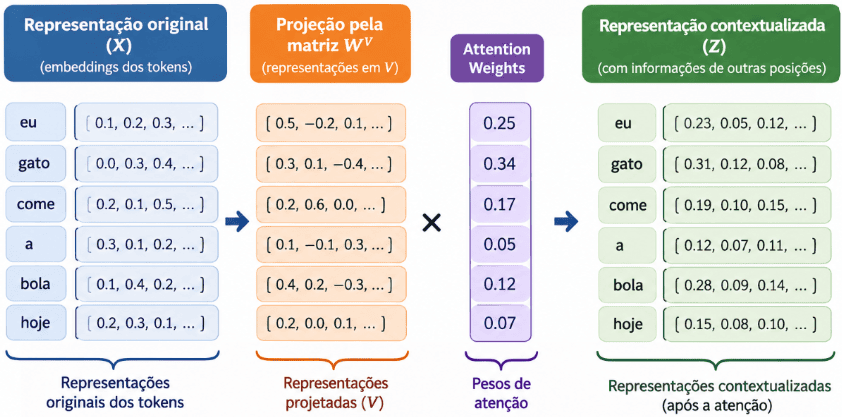

Agora temos os vetores contextualizados utilizando Scaled-Dot-Product Attention! Agora vamos apenas ter uma visão geral para finalizar a analise.

## 3. Resumo Visual

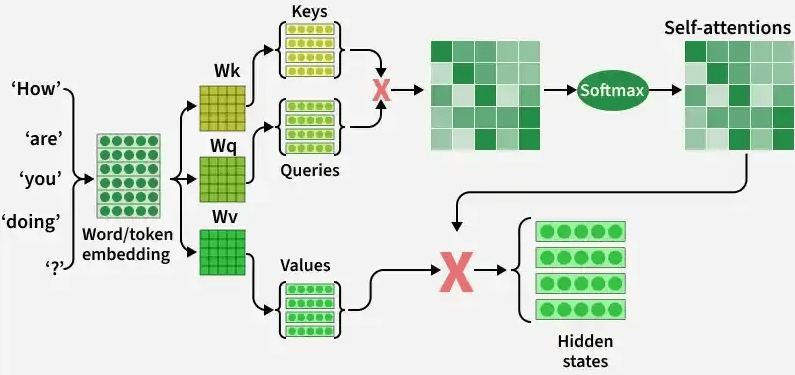

In [5]:
from pathlib import Path
import sys

path = Path('..').resolve()

if path not in sys.path:
    sys.path.append(str(path))

In [ ]:
import math
import torch
from src.functional import softmax

In [ ]:
def scaled_dot_product_attention(
    query: torch.Tensor,
    key: torch.Tensor,
    value: torch.Tensor,
    is_causal: bool = False,
    attn_mask: torch.Tensor | None = None,
) -> torch.Tensor:

    d_k = key.size(-1) # [B, H, Lk, dk]
    scale_factor = math.sqrt(d_k)

# --------------------------------

    # Shapes de entrada
    # Q = [B, H, Lq, d_k]
    # K = [B, H, Lk, d_k]
    
    attn_scores = (
        torch.matmul(
            query,                # Q   -> [B, H, Lq, d_k]
            key.transpose(-2, -1) # K^T -> [B, H, d_k, Lk]
        ) 
        / scale_factor            # sqrt(d_k)
    ) 

    # Shape de Output do Attention Score Matrix:
    # [B, H, Lq, Lk]

    # No anexo abaixo tem uma implementação mais limpa utilizando einsum.

# -------------------------------

    if is_causal:
        if attn_scores is not None:
            raise ValueError("is_causal = True só é permitido com attn_mask=None")

        Lq = query.size(-2) # comprimento da sequencia de queries
        Lk = key.size(-2)   # comprimento da sequencia de keys

        #criando uma matriz triangular inferior booleana -> 1 = True | 0 = False
        causal_mask = torch.tril(
            torch.ones(
                Lq,
                Lk,
                dtype=torch.bool
            )
        )
        attn_scores = attn_scores.masked_fill(
            causal_mask, float('-inf')
        )

    if attn_mask is not None:
        # aplicando outras mascaras como as de padding
        attn_scores = attn_scores.masked_fill(
            attn_mask == 0, float('-inf')
        )

    prob_attn = softmax(
        attn_scores,
        dim=-1
    )

    return torch.matmul(prob_attn, value) 

- Attention Scores com Einsum:
```python
attn_scores = (
    einops.einsum(
        query,
        key,
        "... Lq d_k, ... Lk d_k -> ... Lq Lk" # Lq -> num_queries / Lk -> num_keys
    ) 
    / scale_factor
)
``` 